# Reference-free hydration classifier: ResNet50 conv4 features + logistic-regression ensemble

**Task:** one vein-ROI image → P(dehydrated); a session (one person, one state) → mean of its images. No reference image of the person is needed.

**Model**
- ImageNet ResNet50, **frozen**, cut at `conv4_block6_out` → global average pooling (1024 features per image).
- Ensemble of three L2-regularized logistic regressions (`C = 0.01`, features standardized), averaged:
  1. one classifier on all images,
  2. a separate classifier per landmark (dorsal / wrist),
  3. a classifier trained on original + horizontally flipped images, predicting the average of both (flip TTA).
- Trained **image by image**. Saved as **one `.keras` file** (inputs: image + landmark one-hot).

**Evaluation:** 5-fold cross-validation **by person**, reported at **session level** (accuracy, precision, recall, F1, AUC; positive class = dehydrated).

**Folder layout:** this notebook sits in `H2OPulse/`, data in `H2OPulse/Dataset/<subject>/<hydrated|dehydrated>/<hand>/<landmark>/yolo_vein_roi/*.jpg`, outputs go to `H2OPulse/outputs/`.

In [1]:
# Run once if TensorFlow / scikit-learn are missing, then restart the kernel
# %pip install "tensorflow[and-cuda]" scikit-learn matplotlib pandas

In [2]:
# --- Environment check ---
import os, socket
os.environ.setdefault("TF_CPP_MIN_LOG_LEVEL", "2")
import tensorflow as tf

print("Host:", socket.gethostname())
print("TensorFlow:", tf.__version__)
gpus = tf.config.list_physical_devices("GPU")
print("GPUs:", gpus if gpus else "NONE - running on CPU (slower, but feature extraction still works)")
for g in gpus:
    try:
        tf.config.experimental.set_memory_growth(g, True)
    except RuntimeError as e:
        print("Could not set memory growth:", e)

I0000 00:00:1795501987.028344 3603260 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
I0000 00:00:1795502022.078444 3603260 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.


Host: gpu10
TensorFlow: 2.22.0-rc1
GPUs: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


In [3]:
# --- Configuration ---
PROJECT_DIR = os.getcwd()                              # the H2OPulse folder
DATA_ROOT = os.path.join(PROJECT_DIR, "Dataset")
OUTPUT_DIR = os.path.join(PROJECT_DIR, "outputs")
os.makedirs(OUTPUT_DIR, exist_ok=True)
if not os.path.isdir(DATA_ROOT):
    raise FileNotFoundError(f"DATA_ROOT not found: {DATA_ROOT} (run this notebook from the H2OPulse folder)")

HANDS = ["left_hand", "right_hand"]
LANDMARKS = ["dorsal", "wrist"]
ROI_SUBDIR = "yolo_vein_roi"

IMG_SIZE = (224, 224)
FEATURE_LAYER = "conv4_block6_out"   # ResNet50 stage used as features
LOGREG_C = 0.01                      # inverse L2 strength (smaller = stronger regularization)
N_FOLDS = 5
RANDOM_SEED = 42
BATCH_SIZE = 32
RUN_CV = True                        # cross-validation estimate; set False to only train + save

FEATURES_CACHE = os.path.join(OUTPUT_DIR, f"features_{FEATURE_LAYER}_{IMG_SIZE[0]}.npz")
FEATURES_FLIP_CACHE = os.path.join(OUTPUT_DIR, f"features_{FEATURE_LAYER}_{IMG_SIZE[0]}_hflip.npz")
FINAL_MODEL_PATH = os.path.join(OUTPUT_DIR, "final_conv4_ensemble_reffree.keras")
ROC_CV_PATH = os.path.join(OUTPUT_DIR, "roc_cv_session_ensemble.png")

print("DATA_ROOT :", DATA_ROOT)
print("OUTPUT_DIR:", OUTPUT_DIR)

DATA_ROOT : /bigdata/decristofarolab/mbhui008/olid/H2OPulse/Dataset
OUTPUT_DIR: /bigdata/decristofarolab/mbhui008/olid/H2OPulse/outputs


In [4]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from tensorflow import keras
from tensorflow.keras import layers
from tensorflow.keras.applications import ResNet50
from tensorflow.keras.applications.resnet50 import preprocess_input
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.model_selection import StratifiedGroupKFold
from sklearn.metrics import (
    accuracy_score, auc, average_precision_score, balanced_accuracy_score, classification_report,
    confusion_matrix, f1_score, matthews_corrcoef, precision_recall_fscore_support, precision_score,
    recall_score, roc_auc_score, roc_curve,
)

tf.keras.utils.set_random_seed(RANDOM_SEED)

## 1. Collect images and labels

In [5]:
def list_user_ids(data_root):
    return sorted(
        d for d in os.listdir(data_root)
        if os.path.isdir(os.path.join(data_root, d)) and not d.startswith(".")
    )


def list_images_in_dir(folder):
    if not os.path.isdir(folder):
        return []
    return sorted(
        os.path.join(folder, n) for n in os.listdir(folder)
        if not n.startswith(".")                                   # skip macOS ._ files / .DS_Store
        and n.lower().endswith((".jpg", ".jpeg", ".png"))
        and os.path.isfile(os.path.join(folder, n))
    )


def collect_labeled_paths(user_ids, root=None):
    # Returns (paths, labels) with label 0 = hydrated, 1 = dehydrated
    root = root or DATA_ROOT
    paths_h, paths_d = [], []
    for uid in user_ids:
        for hand in HANDS:
            for lm in LANDMARKS:
                paths_h += list_images_in_dir(os.path.join(root, uid, "hydrated", hand, lm, ROI_SUBDIR))
                paths_d += list_images_in_dir(os.path.join(root, uid, "dehydrated", hand, lm, ROI_SUBDIR))
    paths = np.array(paths_h + paths_d, dtype=object)
    labels = np.array([0] * len(paths_h) + [1] * len(paths_d), dtype=np.int32)
    return paths, labels


def landmark_of(path):
    # .../<landmark>/yolo_vein_roi/<file>  ->  <landmark>
    return os.path.basename(os.path.dirname(os.path.dirname(path)))


all_users = list_user_ids(DATA_ROOT)
all_paths, all_y = collect_labeled_paths(all_users)
_parts = [os.path.relpath(p, DATA_ROOT).split(os.sep) for p in all_paths]
groups = np.array([r[0] for r in _parts])                  # subject id (keeps people out of their own test fold)
sessions = np.array([r[0] + "/" + r[1] for r in _parts])   # subject/condition
lm_of = np.array([landmark_of(p) for p in all_paths])

print(f"Users: {len(all_users)}   images: {len(all_paths)}   sessions: {len(set(sessions))}")
print(f"Class balance: hydrated={int((all_y == 0).sum())}  dehydrated={int((all_y == 1).sum())}")
print("Images per landmark:", {l: int((lm_of == l).sum()) for l in LANDMARKS})

Users: 86   images: 3291   sessions: 172
Class balance: hydrated=1645  dehydrated=1646
Images per landmark: {'dorsal': 1648, 'wrist': 1643}


## 2. Features: frozen ResNet50 → conv4 → global average pooling (original + flipped)

In [6]:
_base = ResNet50(weights="imagenet", include_top=False, input_shape=(*IMG_SIZE, 3))
_base.trainable = False
feature_extractor = keras.Model(
    _base.input,
    layers.GlobalAveragePooling2D(name="gap")(_base.get_layer(FEATURE_LAYER).output),
    name=f"resnet50_{FEATURE_LAYER}_gap",
)


def load_image(path):
    img = tf.io.decode_image(tf.io.read_file(path), channels=3, expand_animations=False)
    img = tf.cast(tf.image.resize(img, IMG_SIZE), tf.float32)
    return preprocess_input(img)


def image_dataset(paths, flip=False):
    fn = (lambda p: tf.image.flip_left_right(load_image(p))) if flip else load_image
    return (tf.data.Dataset.from_tensor_slices(np.asarray(paths, dtype=object))
            .map(fn, num_parallel_calls=tf.data.AUTOTUNE)
            .batch(BATCH_SIZE)
            .prefetch(tf.data.AUTOTUNE))


def cached_features(cache_path, paths, flip):
    # Extract once and cache (re-used if the image list has not changed)
    if os.path.exists(cache_path):
        c = np.load(cache_path, allow_pickle=True)
        if list(c["paths"]) == list(paths):
            print("Loaded cached features:", cache_path)
            return c["X"]
    X = feature_extractor.predict(image_dataset(paths, flip=flip), verbose=1)
    np.savez_compressed(cache_path, X=X, paths=np.asarray(paths, dtype=object))
    print("Saved features:", cache_path)
    return X


X_all = cached_features(FEATURES_CACHE, all_paths, flip=False)
X_flip = cached_features(FEATURES_FLIP_CACHE, all_paths, flip=True)
print("Feature matrices:", X_all.shape, X_flip.shape)

Loaded cached features: /bigdata/decristofarolab/mbhui008/olid/H2OPulse/outputs/features_conv4_block6_out_224.npz
103/103 ━━━━━━━━━━━━━━━━━━━━ 11s 54ms/step
Saved features: /bigdata/decristofarolab/mbhui008/olid/H2OPulse/outputs/features_conv4_block6_out_224_hflip.npz
Feature matrices: (3291, 1024) (3291, 1024)


## 3. Cross-validation by person — session-level results

SESSION-LEVEL results, 5-fold CV by person (positive class = dehydrated, threshold 0.5)

 fold  sessions  accuracy  precision  recall    F1   AUC
    1        34     0.735      0.786   0.647 0.710 0.747
    2        34     0.676      0.650   0.765 0.703 0.654
    3        36     0.778      0.778   0.778 0.778 0.830
    4        34     0.618      0.625   0.588 0.606 0.734
    5        34     0.676      0.688   0.647 0.667 0.799

Mean ± SD across folds:
  accuracy   0.697 ± 0.062
  precision  0.705 ± 0.073
  recall     0.685 ± 0.082
  F1         0.693 ± 0.063
  AUC        0.753 ± 0.068

Pooled over all 172 sessions:
  accuracy   0.698
  precision  0.702
  recall     0.686
  F1         0.694
  AUC        0.753

Saved ROC curve: /bigdata/decristofarolab/mbhui008/olid/H2OPulse/outputs/roc_cv_session_ensemble.png


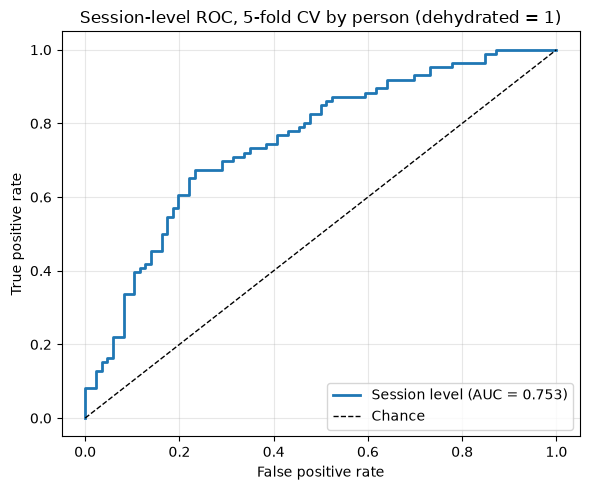

In [7]:
def make_classifier():
    return make_pipeline(StandardScaler(), LogisticRegression(C=LOGREG_C, max_iter=3000))


def fit_ensemble(idx):
    # Train the 3-part ensemble on the images with indices idx
    idx = np.asarray(idx)
    ens = {"all": make_classifier().fit(X_all[idx], all_y[idx]), "landmark": {}}
    for lm in LANDMARKS:
        j = idx[lm_of[idx] == lm]
        ens["landmark"][lm] = make_classifier().fit(X_all[j], all_y[j])
    ens["flip"] = make_classifier().fit(np.vstack([X_all[idx], X_flip[idx]]), np.r_[all_y[idx], all_y[idx]])
    return ens


def predict_ensemble(ens, X, Xf, lms):
    # P(dehydrated) per image = mean of the 3 members
    unknown = set(lms) - set(LANDMARKS)
    if unknown:
        raise ValueError(f"Unknown landmark(s) {unknown}; expected {LANDMARKS}")
    p_all = ens["all"].predict_proba(X)[:, 1]
    p_lm = np.zeros(len(X))
    for lm, m in ens["landmark"].items():
        k = lms == lm
        if k.any():
            p_lm[k] = m.predict_proba(X[k])[:, 1]
    p_flip = 0.5 * (ens["flip"].predict_proba(X)[:, 1] + ens["flip"].predict_proba(Xf)[:, 1])
    return (p_all + p_lm + p_flip) / 3


def session_level(y_img, p_img, sess_img):
    # Average image probabilities per session -> (session labels, session probabilities)
    d = pd.DataFrame({"session": sess_img, "y": y_img, "p": p_img})
    s = d.groupby("session").agg(y=("y", "first"), p=("p", "mean"))
    return s.y.values, s.p.values


def session_metrics(y_s, p_s, thr=0.5):
    yhat = (p_s >= thr).astype(int)
    return {
        "accuracy": accuracy_score(y_s, yhat),
        "precision": precision_score(y_s, yhat, pos_label=1, zero_division=0),
        "recall": recall_score(y_s, yhat, pos_label=1, zero_division=0),
        "F1": f1_score(y_s, yhat, pos_label=1, zero_division=0),
        "AUC": roc_auc_score(y_s, p_s),
    }


if RUN_CV:
    cv = StratifiedGroupKFold(n_splits=N_FOLDS, shuffle=True, random_state=RANDOM_SEED)
    oof = np.zeros(len(all_y))
    fold_rows = []
    for k, (tr, te) in enumerate(cv.split(X_all, all_y, groups), 1):
        assert not set(groups[tr]) & set(groups[te]), "person leakage between train and test"
        ens = fit_ensemble(tr)
        oof[te] = predict_ensemble(ens, X_all[te], X_flip[te], lm_of[te])
        y_s, p_s = session_level(all_y[te], oof[te], sessions[te])
        fold_rows.append({"fold": k, "sessions": len(y_s), **session_metrics(y_s, p_s)})

    folds = pd.DataFrame(fold_rows)
    print(f"SESSION-LEVEL results, {N_FOLDS}-fold CV by person (positive class = dehydrated, threshold 0.5)\n")
    print(folds.round(3).to_string(index=False))
    print("\nMean ± SD across folds:")
    for m in ["accuracy", "precision", "recall", "F1", "AUC"]:
        print(f"  {m:10s} {folds[m].mean():.3f} ± {folds[m].std():.3f}")

    y_sess_all, p_sess_all = session_level(all_y, oof, sessions)
    print(f"\nPooled over all {len(y_sess_all)} sessions:")
    for m, v in session_metrics(y_sess_all, p_sess_all).items():
        print(f"  {m:10s} {v:.3f}")

    fpr, tpr, _ = roc_curve(y_sess_all, p_sess_all)
    fig, ax = plt.subplots(figsize=(6, 5))
    ax.plot(fpr, tpr, lw=2, label=f"Session level (AUC = {auc(fpr, tpr):.3f})")
    ax.plot([0, 1], [0, 1], "k--", lw=1, label="Chance")
    ax.set_xlabel("False positive rate")
    ax.set_ylabel("True positive rate")
    ax.set_title(f"Session-level ROC, {N_FOLDS}-fold CV by person (dehydrated = 1)")
    ax.legend(loc="lower right")
    ax.grid(True, alpha=0.3)
    fig.tight_layout()
    fig.savefig(ROC_CV_PATH, dpi=150, bbox_inches="tight")
    print("\nSaved ROC curve:", ROC_CV_PATH)
    plt.show()
else:
    print("Skipping cross-validation (RUN_CV = False).")

## 4. Train the final ensemble on all users

In [8]:
final_ens = fit_ensemble(np.arange(len(all_y)))
print(f"Trained the ensemble on {len(all_y)} images from {len(all_users)} users "
      "(use the CV results above as the performance estimate)")

Trained the ensemble on 3291 images from 86 users (use the CV results above as the performance estimate)


## 5. Build one `.keras` model (inputs: image + landmark) and save

In [9]:
def to_dense(pipelines):
    # StandardScaler + LogisticRegression -> weights/bias of a Dense(sigmoid) layer (one column per pipeline)
    W, B = [], []
    for pipe in pipelines:
        sc, lr = pipe.named_steps["standardscaler"], pipe.named_steps["logisticregression"]
        w = lr.coef_.ravel() / sc.scale_
        W.append(w)
        B.append(lr.intercept_[0] - np.sum(w * sc.mean_))
    return [np.stack(W, axis=1).astype("float32"), np.array(B, dtype="float32")]


img_in = keras.Input(shape=(*IMG_SIZE, 3), name="image")          # 224x224 RGB after resnet50.preprocess_input
lm_in = keras.Input(shape=(len(LANDMARKS),), name="landmark")      # one-hot in LANDMARKS order
feat = feature_extractor(img_in)
# Horizontal flip built from standard layers only (so the .keras file loads without custom code):
# move width to the last axis, multiply by a fixed reversal matrix, move it back.
_W = IMG_SIZE[1]
hflip_matrix = layers.Dense(_W, use_bias=False, trainable=False, name="hflip_matrix")
img_flip = layers.Permute((1, 3, 2), name="hflip_back")(hflip_matrix(layers.Permute((1, 3, 2), name="hflip_to_w")(img_in)))
feat_flip = feature_extractor(img_flip)

head_all = layers.Dense(1, activation="sigmoid", name="head_all")
head_lm = layers.Dense(len(LANDMARKS), activation="sigmoid", name="head_per_landmark")
head_flip = layers.Dense(1, activation="sigmoid", name="head_flip")

p_all = head_all(feat)
p_lm = layers.Dot(axes=1, name="pick_landmark")([head_lm(feat), lm_in])
p_flip = layers.Average(name="flip_tta")([head_flip(feat), head_flip(feat_flip)])
out = layers.Average(name="ensemble")([p_all, p_lm, p_flip])
final_model = keras.Model({"image": img_in, "landmark": lm_in}, out, name="resnet50_conv4_ensemble_reffree")

hflip_matrix.set_weights([np.eye(_W, dtype="float32")[::-1]])
head_all.set_weights(to_dense([final_ens["all"]]))
head_lm.set_weights(to_dense([final_ens["landmark"][lm] for lm in LANDMARKS]))
head_flip.set_weights(to_dense([final_ens["flip"]]))


def landmark_onehot(paths):
    lms = [landmark_of(p) for p in paths]
    unknown = set(lms) - set(LANDMARKS)
    if unknown:
        raise ValueError(f"Unknown landmark(s) {unknown}; expected {LANDMARKS}")
    return np.eye(len(LANDMARKS), dtype="float32")[[LANDMARKS.index(l) for l in lms]]


def model_dataset(paths):
    # Inputs for final_model: {"image": preprocessed image, "landmark": one-hot}
    ds = tf.data.Dataset.from_tensor_slices((np.asarray(paths, dtype=object), landmark_onehot(paths)))
    return (ds.map(lambda p, l: {"image": load_image(p), "landmark": l}, num_parallel_calls=tf.data.AUTOTUNE)
            .batch(BATCH_SIZE).prefetch(tf.data.AUTOTUNE))


# Sanity check: the Keras model must match the sklearn ensemble
chk = np.random.default_rng(0).choice(len(all_paths), size=min(200, len(all_paths)), replace=False)
p_keras = final_model.predict(model_dataset(all_paths[chk]), verbose=0).ravel()
p_sklearn = predict_ensemble(final_ens, X_all[chk], X_flip[chk], lm_of[chk])
print(f"Max |keras - sklearn| = {np.max(np.abs(p_keras - p_sklearn)):.2e}  (should be ~1e-5 or smaller)")

final_model.save(FINAL_MODEL_PATH)
_reloaded = keras.models.load_model(FINAL_MODEL_PATH)
_diff_reload = np.max(np.abs(_reloaded.predict(model_dataset(all_paths[chk]), verbose=0).ravel() - p_keras))
print("Saved:", FINAL_MODEL_PATH, f"(reload check: max diff {_diff_reload:.1e})")

Max |keras - sklearn| = 5.49e-04  (should be ~1e-5 or smaller)
Saved: /bigdata/decristofarolab/mbhui008/olid/H2OPulse/outputs/final_conv4_ensemble_reffree.keras (reload check: max diff 0.0e+00)


## Using the saved model

```python
from tensorflow import keras
model = keras.models.load_model("outputs/final_conv4_ensemble_reffree.keras")
p = model.predict(model_dataset(paths)).ravel()   # P(dehydrated) per image
session_p = p.mean()                              # one capture session -> average its images
```
`model_dataset` (section 5) prepares both inputs: the image (RGB, 224×224, `resnet50.preprocess_input`) and the landmark one-hot, read from the folder name (`dorsal` / `wrist`).
The final model is trained on **all** subjects, so only test it on **new** people; for existing subjects use the cross-validation results or section 6.

## 6. Evaluate on a test subset (image-level + session-level metrics)

Set `TEST_DATA_ROOT` and `TEST_USERS` at the top of the next cell. Run sections 0–5 first (features are cached, so this is quick).

External data: /bigdata/decristofarolab/mbhui008/olid/H2OPulse/external/clean_vein_masks/Processed_Dataset_v3_s7
User CSV     : /bigdata/decristofarolab/mbhui008/olid/H2OPulse/external/user_selection/users_list_final.csv
Model        : /bigdata/decristofarolab/mbhui008/olid/H2OPulse/outputs/final_conv4_ensemble_reffree.keras
Selected users: 74
Frames: 2960 | scenarios: 592 | visits: 148
Running the ensemble on every frame...
93/93 ━━━━━━━━━━━━━━━━━━━━ 9s 61ms/step
Frame-level AUROC (all frames, no threshold): 0.502
C: 148 visits | combinations per visit: min=625 max=625

Our ensemble on the external dataset — fold mean — threshold: Youden on train users (Table 3 protocol)
Experiment                                      Acc     Prec       F1      Rec     Spec   BalAcc    AUROC
--------------------------------------------------------------------------------------------------------
A. Best frame (*_001)                         0.454    0.466    0.561    0.719    0.189    0.454    0.495
B.

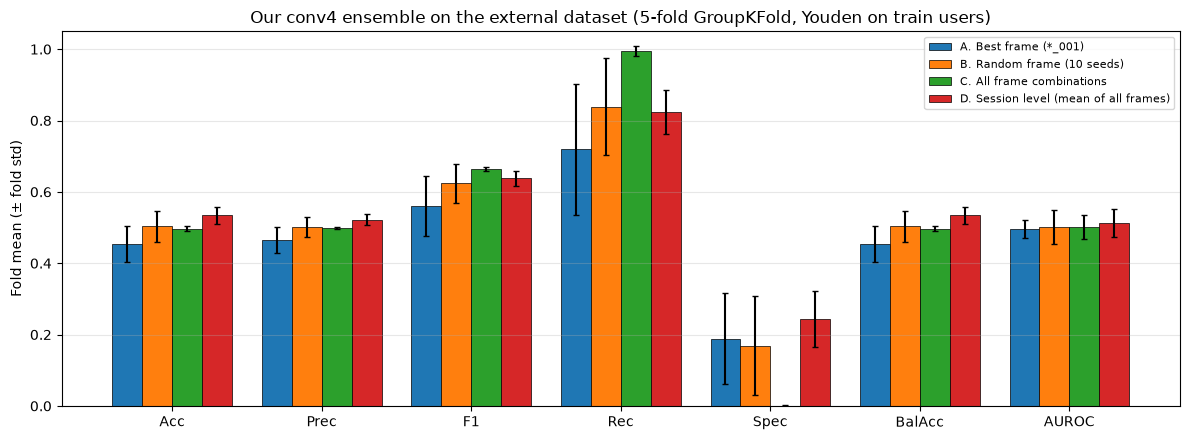

Saved results to /bigdata/decristofarolab/mbhui008/olid/H2OPulse/outputs/external_test


In [11]:
# === 7. External test: our frozen ensemble on the clean-vein-masks dataset (A / B / C / D) ===
# Same protocol as §6e-2 / combinations cell in h2opulse_model_experiment.ipynb:
#   users from users_list_final.csv (same selection rule), hydrated-vs-reference folder from hyd_ref_d / hyd_ref_w,
#   5 frames per modality, GroupKFold(5) by user, model FROZEN (no retraining) - folds only pick the Youden
#   threshold on each fold's training users; fixed thresholds 0.44 and 0.5 also reported.
#   A. Best frame   : *_001 (DatasetCurator rank 1) per modality  -> visit = mean of modality probs
#   B. Random frame : one random frame per modality, 10 seeds     -> visit = mean of modality probs
#   C. All frame combinations: every 1-frame-per-modality combination (5^4 = 625 per visit) is one test sample
#   D. Session level: mean probability of ALL frames of the visit (as in our notebook)
import glob
from collections import defaultdict
from sklearn.model_selection import GroupKFold

EXT_ROOT = os.path.join(PROJECT_DIR, "external")
EXT_OUT = os.path.join(OUTPUT_DIR, "external_test")
os.makedirs(EXT_OUT, exist_ok=True)

EXT_MODALITIES = ["left_dorsal", "right_dorsal", "left_wrist", "right_wrist"]
EXT_DORSAL = ["left_dorsal", "right_dorsal"]
EXT_N_FRAMES = 5
EXT_SEED = 801                 # SEED in h2opulse_model_experiment.ipynb (same random-frame draws)
EXT_N_RANDOM_REPEATS = 10
EXT_MIN_MODALITIES = 2
EXT_N_SPLITS = 5
EXT_FIXED_THRESHOLDS = [0.44, 0.5]
EXT_METRICS = ["Accuracy", "Precision", "F1", "Recall (Sensitivity)", "Specificity", "Balanced Accuracy", "AUROC"]


def _find(root, name, want_dir):
    for dirpath, dirnames, filenames in os.walk(root):
        if name in (dirnames if want_dir else filenames):
            return os.path.join(dirpath, name)
    return None


EXT_DATA_ROOT = _find(EXT_ROOT, "Processed_Dataset_v3_s7", want_dir=True)
EXT_CSV = _find(EXT_ROOT, "users_list_final.csv", want_dir=False) or _find(EXT_ROOT, "users_list_v3.csv", want_dir=False)
if EXT_DATA_ROOT is None or EXT_CSV is None:
    raise FileNotFoundError(f"Could not find Processed_Dataset_v3_s7/ and users_list_final.csv under {EXT_ROOT}")
print("External data:", EXT_DATA_ROOT)
print("User CSV     :", EXT_CSV)
print("Model        :", FINAL_MODEL_PATH)

# ---------------------------------------------------------------- users (same rule as their §2) ----
_raw = pd.read_csv(EXT_CSV)
_u = _raw.iloc[:, :5].copy()
_u.columns = ["user_id", "ok_d", "hyd_ref_d", "ok_w", "hyd_ref_w"]
_ok = {(1, 1), (1, 0), (0, 1), (1, -1), (-1, 1)}
_u = _u[[(d, w) in _ok for d, w in zip(_u.ok_d, _u.ok_w)]].reset_index(drop=True)
ext_meta = _u.set_index("user_id").to_dict("index")
ext_users = np.array(sorted(set(_u.user_id)))
print(f"Selected users: {len(ext_users)}")

# ---------------------------------------------------------------- frames (same folder rule as get_folder) ----
frame_rows, missing = [], []
for uid in ext_users:
    meta = ext_meta[uid]
    for label, state in [(1, "dehydrated"), (0, "hydrated")]:
        for mod in EXT_MODALITIES:
            use_h = int(meta["hyd_ref_d" if mod in EXT_DORSAL else "hyd_ref_w"])
            sub = "dehydrated" if state == "dehydrated" else ("hydrated" if use_h else "reference")
            folder = os.path.join(EXT_DATA_ROOT, uid, sub, mod)
            paths = sorted(glob.glob(os.path.join(folder, "*.png")))[:EXT_N_FRAMES]
            if not paths:
                missing.append(folder)
            for fi, p in enumerate(paths):
                frame_rows.append({"user_id": uid, "label": label, "modality": mod,
                                   "landmark": "dorsal" if mod in EXT_DORSAL else "wrist",
                                   "frame_idx": fi, "frame_name": os.path.basename(p), "path": p})
ext_frames = pd.DataFrame(frame_rows)
if missing:
    print(f"[WARN] {len(missing)} empty/missing modality folders (e.g. {missing[0]})")
print(f"Frames: {len(ext_frames)} | scenarios: {ext_frames.groupby(['user_id', 'label', 'modality']).ngroups} "
      f"| visits: {ext_frames.groupby(['user_id', 'label']).ngroups}")

# ---------------------------------------------------------------- predict every frame once ----
ext_model = keras.models.load_model(FINAL_MODEL_PATH)


def _ext_dataset(paths, landmarks):
    onehot = np.eye(len(LANDMARKS), dtype="float32")[[LANDMARKS.index(l) for l in landmarks]]
    ds = tf.data.Dataset.from_tensor_slices((np.asarray(paths, dtype=object), onehot))
    return (ds.map(lambda p, l: {"image": load_image(p), "landmark": l}, num_parallel_calls=tf.data.AUTOTUNE)
            .batch(BATCH_SIZE).prefetch(tf.data.AUTOTUNE))


print("Running the ensemble on every frame...")
ext_frames["prob"] = ext_model.predict(_ext_dataset(ext_frames.path.tolist(), ext_frames.landmark.tolist()),
                                       verbose=1).ravel()
ext_frames.to_csv(os.path.join(EXT_OUT, "frame_probs.csv"), index=False)
print(f"Frame-level AUROC (all frames, no threshold): {roc_auc_score(ext_frames.label, ext_frames.prob):.3f}")

scen = {}
for key, sub in ext_frames.sort_values("frame_idx").groupby(["user_id", "label", "modality"]):
    scen[(key[0], int(key[1]), key[2])] = sub.prob.values
scen_keys = sorted(scen)


# ---------------------------------------------------------------- helpers (same as their notebook) ----
def youden_threshold(y_true, y_prob, recall_weight=1.25):
    if len(set(y_true)) < 2:
        return 0.5
    fpr, tpr, thresh = roc_curve(y_true, y_prob)
    idx = int(np.argmax(recall_weight * tpr - fpr))
    return float(np.clip(float(thresh[idx]), 0.05, 0.95))


def ext_metrics(y, p, t):
    y, p = np.asarray(y), np.asarray(p)
    pred = (p >= t).astype(int)
    return {
        "Accuracy": accuracy_score(y, pred),
        "Precision": precision_score(y, pred, zero_division=0),
        "F1": f1_score(y, pred, zero_division=0),
        "Recall (Sensitivity)": recall_score(y, pred, zero_division=0),
        "Specificity": recall_score(y, pred, pos_label=0, zero_division=0),
        "Balanced Accuracy": balanced_accuracy_score(y, pred),
        "AUROC": roc_auc_score(y, p) if len(set(y)) > 1 else 0.5,
    }


def visit_samples(mode, frame_choice=None):
    """visit (user, label) -> array of test-sample probabilities for that visit."""
    per_visit = defaultdict(list)
    for k in scen_keys:
        per_visit[(k[0], k[1])].append(scen[k])
    out = {}
    for v, arrs in per_visit.items():
        if len(arrs) < EXT_MIN_MODALITIES:
            continue
        if mode == "frame":            # A / B: one chosen frame per modality, visit = mean over modalities
            mods = [k for k in scen_keys if (k[0], k[1]) == v]
            out[v] = np.array([np.mean([scen[k][frame_choice[k]] for k in mods])])
        elif mode == "combos":         # C: every combination of one frame per modality
            out[v] = np.mean(np.stack(np.meshgrid(*arrs, indexing="ij")), axis=0).ravel()
        elif mode == "session":        # D: mean of all frames of the visit
            out[v] = np.array([np.concatenate(arrs).mean()])
    return out


def ext_cv(samples):
    gkf = GroupKFold(n_splits=EXT_N_SPLITS)
    rows, fold_t, oy, op = [], [], [], []
    for f, (tr_i, te_i) in enumerate(gkf.split(ext_users, groups=ext_users), 1):
        tr_u, te_u = set(ext_users[tr_i]), set(ext_users[te_i])
        tr_k = sorted(k for k in samples if k[0] in tr_u)
        te_k = sorted(k for k in samples if k[0] in te_u)
        tr_y = np.concatenate([np.full(len(samples[k]), k[1]) for k in tr_k])
        tr_p = np.concatenate([samples[k] for k in tr_k])
        te_y = np.concatenate([np.full(len(samples[k]), k[1]) for k in te_k])
        te_p = np.concatenate([samples[k] for k in te_k])
        t = youden_threshold(tr_y, tr_p)
        fold_t.append(t); oy.append(te_y); op.append(te_p)
        base = {"fold": f, "n_test_visits": len(te_k), "n_test_samples": len(te_y)}
        rows.append({**base, "threshold": "youden_train", "t": t, **ext_metrics(te_y, te_p, t)})
        for tf_ in EXT_FIXED_THRESHOLDS:
            rows.append({**base, "threshold": f"fixed_{tf_}", "t": tf_, **ext_metrics(te_y, te_p, tf_)})
    oy, op = np.concatenate(oy), np.concatenate(op)
    t_mean = float(np.mean(fold_t))
    pooled = {"youden_train": ext_metrics(oy, op, t_mean)}
    for tf_ in EXT_FIXED_THRESHOLDS:
        pooled[f"fixed_{tf_}"] = ext_metrics(oy, op, tf_)
    return pd.DataFrame(rows), pooled, t_mean


summary_rows, fold_tables = [], []


def add_summary(name, fdf, pooled, t_mean, repeat_std=None):
    for thr in fdf.threshold.unique():
        sub = fdf[fdf.threshold == thr]
        row = {"Experiment": name, "threshold": thr,
               "t (mean fold)": t_mean if thr == "youden_train" else float(thr.split("_", 1)[1])}
        for m in EXT_METRICS:
            row[f"{m} (fold mean)"] = sub[m].mean()
            row[f"{m} (fold std)"] = sub[m].std()
            row[f"{m} (pooled OOF)"] = pooled[thr][m]
            if repeat_std is not None:
                row[f"{m} (std across repeats)"] = repeat_std[thr][m]
        summary_rows.append(row)


# ---------------------------------------------------------------- run A, B, C, D ----
best_idx = {k: 0 for k in scen_keys}                         # *_001 = DatasetCurator rank 1
fdf, pooled, t_ = ext_cv(visit_samples("frame", best_idx))
fdf.insert(0, "experiment", "A. Best frame"); fold_tables.append(fdf)
add_summary("A. Best frame (*_001)", fdf, pooled, t_)

rep_f, rep_p, rep_t, rep_means = [], [], [], defaultdict(list)
for r in range(EXT_N_RANDOM_REPEATS):
    rng = np.random.default_rng(EXT_SEED + r)
    rand_idx = {k: int(rng.integers(len(scen[k]))) for k in scen_keys}
    fdf_r, pooled_r, t_r = ext_cv(visit_samples("frame", rand_idx))
    fdf_r.insert(0, "experiment", "B. Random frame"); fdf_r.insert(1, "repeat", r)
    rep_f.append(fdf_r); rep_p.append(pooled_r); rep_t.append(t_r)
    for thr in fdf_r.threshold.unique():
        rep_means[thr].append(fdf_r[fdf_r.threshold == thr][EXT_METRICS].mean())
fdf_rand = pd.concat(rep_f, ignore_index=True); fold_tables.append(fdf_rand)
pooled_rand = {thr: {m: float(np.mean([p[thr][m] for p in rep_p])) for m in EXT_METRICS} for thr in rep_means}
rand_std = {thr: pd.DataFrame(v).std().to_dict() for thr, v in rep_means.items()}
add_summary(f"B. Random frame ({EXT_N_RANDOM_REPEATS} seeds)", fdf_rand, pooled_rand, float(np.mean(rep_t)), rand_std)

combo = visit_samples("combos")
print(f"C: {len(combo)} visits | combinations per visit: min={min(map(len, combo.values()))} "
      f"max={max(map(len, combo.values()))}")
fdf, pooled, t_ = ext_cv(combo)
fdf.insert(0, "experiment", "C. All frame combinations"); fold_tables.append(fdf)
add_summary("C. All frame combinations", fdf, pooled, t_)

fdf, pooled, t_ = ext_cv(visit_samples("session"))
fdf.insert(0, "experiment", "D. Session level"); fold_tables.append(fdf)
add_summary("D. Session level (mean of all frames)", fdf, pooled, t_)

ext_summary = pd.DataFrame(summary_rows)
pd.concat(fold_tables, ignore_index=True).to_csv(os.path.join(EXT_OUT, "folds.csv"), index=False)
ext_summary.to_csv(os.path.join(EXT_OUT, "summary.csv"), index=False)

# ---------------------------------------------------------------- report ----
_short = {"Accuracy": "Acc", "Precision": "Prec", "F1": "F1", "Recall (Sensitivity)": "Rec",
          "Specificity": "Spec", "Balanced Accuracy": "BalAcc", "AUROC": "AUROC"}
_tags = {"youden_train": "Youden on train users (Table 3 protocol)",
         "fixed_0.44": "fixed t=0.44 (H2OPulse reported threshold)",
         "fixed_0.5": "fixed t=0.5 (default sigmoid)"}
for thr in ["youden_train"] + [f"fixed_{t}" for t in EXT_FIXED_THRESHOLDS]:
    for kind in ["fold mean", "pooled OOF"]:
        print("\n" + "=" * 104)
        print(f"Our ensemble on the external dataset — {kind} — threshold: {_tags[thr]}")
        print("=" * 104)
        print(f"{'Experiment':<42}" + "".join(f"{_short[m]:>9}" for m in EXT_METRICS))
        print("-" * 104)
        for _, row in ext_summary[ext_summary.threshold == thr].iterrows():
            print(f"{row['Experiment']:<42}" + "".join(f"{row[f'{m} ({kind})']:>9.3f}" for m in EXT_METRICS))

print("\nFold mean ± std (Youden on train users):")
for _, row in ext_summary[ext_summary.threshold == "youden_train"].iterrows():
    print(f"  {row['Experiment']:<42}" + "  ".join(
        f"{_short[m]}={row[f'{m} (fold mean)']:.3f}±{row[f'{m} (fold std)']:.3f}"
        for m in ["Accuracy", "F1", "Balanced Accuracy", "AUROC"]))

_y = ext_summary[ext_summary.threshold == "youden_train"].set_index("Experiment")
_best = _y["Accuracy (fold mean)"].idxmax()
print(f"\nBest by fold-mean accuracy (Youden): {_best}  "
      f"(Acc {_y.loc[_best, 'Accuracy (fold mean)']:.3f}, AUROC {_y.loc[_best, 'AUROC (fold mean)']:.3f})")

fig, ax = plt.subplots(figsize=(12, 4.5))
w = 0.8 / len(_y)
xs = np.arange(len(EXT_METRICS))
for i, (name, row) in enumerate(_y.iterrows()):
    ax.bar(xs + (i - (len(_y) - 1) / 2) * w, [row[f"{m} (fold mean)"] for m in EXT_METRICS], w,
           yerr=[row[f"{m} (fold std)"] for m in EXT_METRICS], capsize=2, label=name,
           edgecolor="black", linewidth=0.5)
ax.set_xticks(xs); ax.set_xticklabels([_short[m] for m in EXT_METRICS])
ax.set_ylim(0, 1.05); ax.set_ylabel("Fold mean (± fold std)")
ax.set_title("Our conv4 ensemble on the external dataset (5-fold GroupKFold, Youden on train users)")
ax.legend(fontsize=8); ax.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.savefig(os.path.join(EXT_OUT, "experiments_youden.png"), dpi=150)
plt.show()
print("Saved results to", EXT_OUT)